In [4]:
import pandas as pd
import json

# 1. Cargar el archivo original
df = pd.read_csv(r"C:\Users\aleja\OneDrive\Documentos\uni\bd\Conversaciones_chatbot_Salud_mental.csv")
row = df.iloc[0]

intents_limpios = []

# Iterar sobre las 80 intenciones identificadas
for i in range(80):
    tag_col = f"intents[{i}].tag"
    if tag_col in row and pd.notna(row[tag_col]):
        tag = str(row[tag_col])

        # Extraer patrones (mensajes de usuario)
        patterns = [
            str(row[c]) for c in df.columns
            if f"intents[{i}].patterns" in c and pd.notna(row[c])
        ]

        # Extraer respuestas del bot
        responses = [
            str(row[c]) for c in df.columns
            if f"intents[{i}].responses" in c and pd.notna(row[c])
        ]

        intents_limpios.append({
            "intent_id": i + 1,
            "categoria": tag,
            "num_patrones": len(patterns),
            "num_respuestas": len(responses),
            "patrones": patterns,
            "respuestas": responses
        })

# 2. Guardar el archivo JSON formateado
with open("salud_mental_limpio.json", "w", encoding="utf-8") as f:
    json.dump(intents_limpios, f, indent=2, ensure_ascii=False)

print(f"Procesadas {len(intents_limpios)} categorias con exito.")

Procesadas 80 categorias con exito.


Ecuacion: Y = 0.430X + 0.707
Coeficiente R2: 0.593


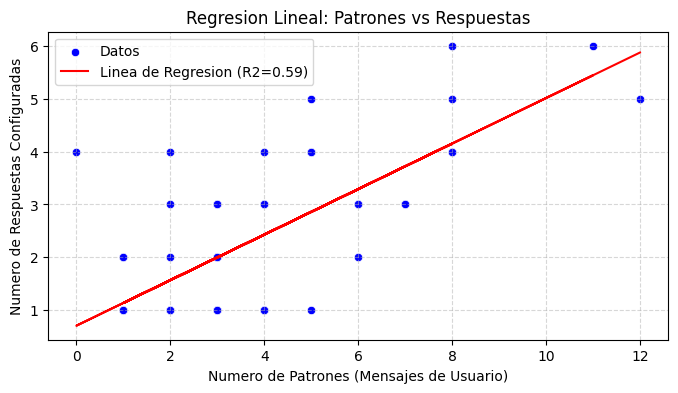

In [1]:
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Conexion a MongoDB
client = pymongo.MongoClient("mongodb://localhost:27017/")
db = client["salud_mental_db"]
collection = db["intenciones"]

# 2. Cargar datos en Pandas
documentos = list(collection.find({}, {"_id": 0, "categoria": 1, "num_patrones": 1, "num_respuestas": 1}))
df = pd.DataFrame(documentos)

# 3. Regresion Lineal Simple
X = df[["num_patrones"]]
y = df["num_respuestas"]

modelo = LinearRegression()
modelo.fit(X, y)
y_pred = modelo.predict(X)

# 4. Metricas
m = modelo.coef_[0]
b = modelo.intercept_
r2 = r2_score(y, y_pred)

print(f"Ecuacion: Y = {m:.3f}X + {b:.3f}")
print(f"Coeficiente R2: {r2:.3f}")

# 5. Visualizacion
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="num_patrones", y="num_respuestas", color="blue", label="Datos")
plt.plot(X, y_pred, color="red", label=f"Linea de Regresion (R2={r2:.2f})")
plt.title("Regresion Lineal: Patrones vs Respuestas")
plt.xlabel("Numero de Patrones (Mensajes de Usuario)")
plt.ylabel("Numero de Respuestas Configuradas")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()